# The Big Short: When Mortgages Go Wrong
**Hackathon 5 — Model Showdown | SDG 8**

**Question:** Can origination-time information predict whether a Freddie Mac mortgage originated in 2006 reaches 90+ days delinquency within its first 24 months?

**Intended user:** an institutional mortgage portfolio credit-risk analyst using Freddie Mac's published performance data. The prediction is for research and portfolio review, **not** an automatic decision to deny a loan.

**Primary metric:** recall for class 1 (serious delinquency). Missing genuinely delinquent loans is important, but precision and false alarms matter too. We will not choose a model based on recall alone.

**Before running:** Download the 2006 **Standard Sample** origination and monthly performance files from [Freddie Mac](https://www.freddiemac.com/research/datasets/sf-loanlevel-dataset) after checking registration and data-use terms. Upload both files into Colab or place them beside this notebook. Set their paths in the next cell. This notebook does not invent data or scores. See README for the source and limitations.

In [11]:
from pathlib import Path
import sys, zipfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score, f1_score, confusion_matrix
print('Python',sys.version.split()[0], 'pandas',pd.__version__,'numpy',np.__version__,'scikit-learn',sklearn.__version__)
# Put sample_2006.zip beside the notebook (or upload it to Colab's Files panel).
ZIP_PATH = Path('sample_2006.zip')
if not ZIP_PATH.exists():
    raise FileNotFoundError('Upload sample_2006.zip to the Colab Files panel, then choose Runtime > Run all.')
archive = zipfile.ZipFile(ZIP_PATH)
assert {'sample_orig_2006.txt','sample_perf_2006.txt'} <= set(archive.namelist())
print('Using original Freddie Mac 2006 sample ZIP')


Python 3.13.16 pandas 2.2.3 numpy 2.1.3 scikit-learn 1.6.1
Using original Freddie Mac 2006 sample ZIP


## 1. Load the original data
We read the official 2006 Standard Sample ZIP directly, so no manual unzipping or extra installations are needed. The origination file has one row per loan. The performance file has many monthly records per loan. We use only the fields needed for the research question.


In [12]:
orig_cols = ['credit_score','first_payment_date','first_time_homebuyer','maturity_date','msa','mi_pct','num_units','occupancy','cltv','dti','original_upb','ltv','interest_rate','channel','prepayment_penalty','product_type','state','property_type','postal_code','loan_id','loan_purpose','term','num_borrowers','seller','servicer','super_conforming','pre_harp_id','program_indicator','harp_indicator','property_valuation_method','interest_only']
# Only the first five columns of the performance file are required for our target.
orig_keep = ['loan_id','first_payment_date','credit_score','first_time_homebuyer','num_units','occupancy','cltv','dti','original_upb','ltv','interest_rate','channel','state','property_type','loan_purpose','term','num_borrowers']
orig_idx = {name:i for i,name in enumerate(orig_cols)}
def read_orig():
    indexes=[orig_idx[c] for c in orig_keep]
    with archive.open('sample_orig_2006.txt') as f:
        return pd.read_csv(f,sep='|',header=None,usecols=indexes,dtype=str).rename(columns={orig_idx[c]:c for c in orig_keep})
orig=read_orig()
print('Origination records:',orig.shape,'unique loan IDs:',orig.loan_id.nunique())
assert not orig.loan_id.duplicated().any(), 'Check duplicate loan IDs before splitting'
display(orig.head(3))


Origination records: (50000, 17) unique loan IDs: 50000


,credit_score,first_payment_date,first_time_homebuyer,num_units,occupancy,cltv,dti,original_upb,ltv,interest_rate,channel,state,property_type,loan_id,loan_purpose,term,num_borrowers
0,776,200603,N,1,P,82,45,180000,82,6.5,R,TX,SF,F06Q10000059,P,360,2
1,639,200603,N,1,P,81,42,337000,81,6.375,R,RI,SF,F06Q10000079,P,360,2
2,707,200603,N,1,P,82,46,155000,82,6.375,R,TX,SF,F06Q10000090,N,360,2


## 2. Build the target carefully
Class 1 = delinquency status 3 or higher (ordinary numeric codes) within loan ages 1–24. Class 0 = no such event **and** a record observed at age 24. Loans that disappear before 24 months without a positive event are excluded rather than incorrectly treated as negatives. This conservative rule may remove paid-off loans and change the population; we report how many. Check special delinquency codes and the meaning of loan age in the official guide.

In [13]:
# Read the performance file in chunks so the 370 MB text file does not fill Colab memory.
# We use columns 0 (ID), 3 (delinquency status), and 4 (loan age).
# Code 3 = 90-119 days late; 4-9 are more severe. Non-numeric status codes
# are not silently counted as negatives.
records=[]
with archive.open('sample_perf_2006.txt') as f:
    for chunk in pd.read_csv(f,sep='|',header=None,usecols=[0,3,4],dtype=str,chunksize=200000):
        chunk.columns=['loan_id','status','loan_age']
        chunk['loan_age']=pd.to_numeric(chunk['loan_age'],errors='coerce')
        chunk=chunk.loc[chunk.loan_age.between(1,24)].copy()
        chunk['status_num']=pd.to_numeric(chunk.status,errors='coerce')
        chunk['positive']=chunk.status_num.between(3,9)
        chunk['known']=chunk.status_num.between(0,9)
        records.append(chunk[['loan_id','loan_age','positive','known']])
window=pd.concat(records,ignore_index=True)
# Duplicated monthly rows, if any, should not count as two months of follow-up.
print('Repeated loan-age rows:',window.duplicated(['loan_id','loan_age']).sum())
window=window.drop_duplicates(['loan_id','loan_age'],keep='first')
summary=window.groupby('loan_id').agg(positive=('positive','max'),known_months=('known','sum'),observed_months=('loan_age','nunique'),last_age=('loan_age','max'))
summary['eligible']=summary.positive | ((summary.last_age>=24)&(summary.known_months>=24)&(summary.observed_months>=24))
print('Observed loans:',len(summary),'Excluded due to incomplete negative follow-up:',int((~summary.eligible).sum()))
labels=summary.loc[summary.eligible,'positive'].astype(int).rename('target')
data=orig.merge(labels,left_on='loan_id',right_index=True,how='inner',validate='one_to_one')
print('Final labelled rows:',len(data),'target counts:',data.target.value_counts().to_dict())
assert len(data)>=300 and data.target.nunique()==2


Repeated loan-age rows: 67860
Observed loans: 49732 Excluded due to incomplete negative follow-up: 12058
Final labelled rows: 37674 target counts: {0: 36687, 1: 987}


## 3. Explore data and check quality
Look at missingness, duplicates, suspicious numeric values and class imbalance before modelling. Placeholder values in historical data may mean 'unknown', not a real score. We explicitly replace several common placeholders below; verify them with the Freddie Mac guide.

Raw rows 50000 final rows 37674 excluded 12326
Missing values (%)


,0
dti,2.0
credit_score,0.1
num_borrowers,0.1
num_units,0.0
occupancy,0.0
cltv,0.0
first_time_homebuyer,0.0
original_upb,0.0
ltv,0.0
channel,0.0


Duplicate loan IDs: 0 duplicate feature vectors: 0
Target class balance


,proportion
target,
0,0.9738
1,0.0262


,count,mean,std,min,25%,50%,75%,max
credit_score,37638.0,722.931001,58.012768,300.0,681.000,728.000,772.000,844.0
num_units,37674.0,1.027711,0.207181,1.0,1.000,1.000,1.000,4.0
cltv,37668.0,72.788892,18.870157,6.0,63.000,79.000,86.000,160.0
dti,36914.0,36.461722,12.142498,1.0,28.000,36.000,45.000,65.0
original_upb,37674.0,176163.375272,93273.944124,10000.0,105000.000,155000.000,229000.000,802000.0
ltv,37668.0,70.233832,17.381123,6.0,61.000,77.000,80.000,102.0
interest_rate,37674.0,6.385376,0.382635,3.5,6.125,6.375,6.625,8.5
term,37674.0,335.319292,60.088079,60.0,360.000,360.000,360.000,480.0
num_borrowers,37655.0,1.547683,0.497728,1.0,1.000,2.000,2.000,2.0


credit_score out of expected range: 0
dti out of expected range: 0
ltv out of expected range: 0
cltv out of expected range: 1
interest_rate out of expected range: 0
original_upb out of expected range: 0


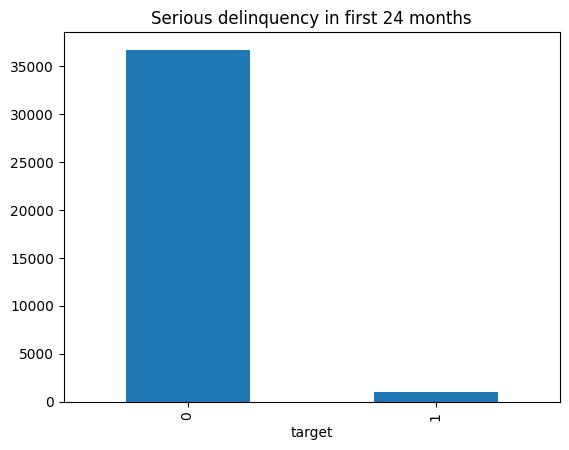

In [14]:
features=['credit_score','first_time_homebuyer','num_units','occupancy','cltv','dti','original_upb','ltv','interest_rate','channel','state','property_type','loan_purpose','term','num_borrowers']
num=['credit_score','num_units','cltv','dti','original_upb','ltv','interest_rate','term','num_borrowers']
cat=[c for c in features if c not in num]
for c in num:data[c]=pd.to_numeric(data[c],errors='coerce')
for c,vals in {'credit_score':[9999], 'dti':[999], 'ltv':[999], 'cltv':[999], 'num_borrowers':[99]}.items():data[c]=data[c].replace(vals,np.nan)
print('Raw rows',len(orig),'final rows',len(data),'excluded',len(orig)-len(data))
print('Missing values (%)');display((100*data[features].isna().mean()).round(1).sort_values(ascending=False))
print('Duplicate loan IDs:',data.loan_id.duplicated().sum(),'duplicate feature vectors:',data[features].duplicated().sum())
print('Target class balance');display(data.target.value_counts(normalize=True).round(4))
display(data[num].describe().T)
for c,low,high in [('credit_score',300,850),('dti',0,65),('ltv',0,150),('cltv',0,150),('interest_rate',0,25),('original_upb',1,2000000)]:
    print(c,'out of expected range:',int(((data[c]<low)|(data[c]>high)).sum()))
data.target.value_counts().sort_index().plot.bar(title='Serious delinquency in first 24 months');plt.show()


## 4. Split first, preprocess inside pipelines
After constructing labels and checking the data, we take a fixed stratified subset of at most 12,000 loans so KNN tuning can finish in a normal Colab session. This changes the population we evaluate: our reported results apply to this sample, not every loan in Freddie Mac's dataset. We then reserve 20% as untouched test data. Missing-value imputation, scaling and categorical encoding are fitted separately inside each training fold, avoiding leakage.


In [15]:
# For a classroom-sized, repeatable KNN comparison, use a fixed stratified
# subsample of up to 12,000 labelled loans. No class is deliberately oversampled.
# This is a computational choice, not a claim about the entire 2006 portfolio.
if len(data)>12000:
    data,_=train_test_split(data,train_size=12000,stratify=data.target,random_state=42)
print('Modelled sample:',len(data),'class balance:',data.target.value_counts().to_dict())
X=data[features].copy();y=data.target.copy()
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42,stratify=y)
pre=ColumnTransformer([('numeric',Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),num),('categorical',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('encoder',OneHotEncoder(handle_unknown='ignore'))]),cat)])
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=42)
print('Train/test:',len(X_train),len(X_test))


Modelled sample: 12000 class balance: {0: 11686, 1: 314}
Train/test: 9600 2400


## 5. Baseline and tuned models
The dummy predicts the majority class. We compare it with KNN, logistic regression and a decision tree, all scored using **recall for class 1**. We also consider precision and F1 before recommending anything. To keep Colab runtime reasonable, the grid is deliberately small.

In [16]:
models={
 'KNN':(KNeighborsClassifier(),{'model__n_neighbors':[5,15,35],'model__weights':['uniform','distance']}),
 'Logistic regression':(LogisticRegression(max_iter=1500,random_state=42,class_weight='balanced'),{'model__C':[0.1,1,10]}),
 'Decision tree':(DecisionTreeClassifier(random_state=42,class_weight='balanced'),{'model__max_depth':[3,6,10],'model__min_samples_leaf':[20,100]})}
# Fitting KNN on all 50k sample loans can be slow; do not silently subsample.
results=[]; fitted={}; tuning=[]
dummy=Pipeline([('prep',pre),('model',DummyClassifier(strategy='most_frequent'))])
dummy.fit(X_train,y_train);fitted['Dummy baseline']=dummy
for name,(model,params) in models.items():
    print('Tuning',name)
    search=GridSearchCV(Pipeline([('prep',pre),('model',model)]),params,scoring='recall',cv=cv,n_jobs=1,return_train_score=True)
    search.fit(X_train,y_train)
    fitted[name]=search.best_estimator_
    t=pd.DataFrame(search.cv_results_);t['model']=name;tuning.append(t)
    print(name,'best:',search.best_params_,'CV recall:',round(search.best_score_,3))
# CV summary is based on training folds only, including dummy.
for name,est in fitted.items():
    scores=(cross_val_score(est,X_train,y_train,cv=cv,scoring='recall',n_jobs=1) if name=='Dummy baseline' else next(t for t in tuning if t.model.iloc[0]==name).sort_values('rank_test_score').iloc[0][[f'split{k}_test_score' for k in range(cv.n_splits)]].to_numpy(dtype=float))
    train_recall=recall_score(y_train,est.predict(X_train),zero_division=0)
    results.append({'model':name,'best_params': ('most_frequent' if name=='Dummy baseline' else next(t for t in tuning if t.model.iloc[0]==name).sort_values('rank_test_score').iloc[0]['params']), 'train_recall':train_recall,'cv_recall_mean':scores.mean(),'cv_recall_std':scores.std()})
comparison=pd.DataFrame(results)
display(comparison)

Tuning KNN
KNN best: {'model__n_neighbors': 5, 'model__weights': 'uniform'} CV recall: 0.0
Tuning Logistic regression
Logistic regression best: {'model__C': 0.1} CV recall: 0.729
Tuning Decision tree
Decision tree best: {'model__max_depth': 3, 'model__min_samples_leaf': 100} CV recall: 0.828


,model,best_params,train_recall,cv_recall_mean,cv_recall_std
0,Dummy baseline,most_frequent,0.000000,0.000000,0.000000
1,KNN,"{'model__n_neighbors': 5, 'model__weights': 'u...",0.031873,0.000000,0.000000
2,Logistic regression,{'model__C': 0.1},0.820717,0.728868,0.038610
3,Decision tree,"{'model__max_depth': 3, 'model__min_samples_le...",0.816733,0.828409,0.051175


## 6. Hyperparameter comparison
This table shows how tuning affected recall across CV folds; we did not use the test set to choose settings.

,model,params,mean_test_score,std_test_score
10,Decision tree,"{'model__max_depth': 3, 'model__min_samples_le...",0.828409,0.051175
9,Decision tree,"{'model__max_depth': 3, 'model__min_samples_le...",0.816456,0.049361
12,Decision tree,"{'model__max_depth': 6, 'model__min_samples_le...",0.721266,0.047170
14,Decision tree,"{'model__max_depth': 10, 'model__min_samples_l...",0.689233,0.029214
11,Decision tree,"{'model__max_depth': 6, 'model__min_samples_le...",0.649455,0.059063
13,Decision tree,"{'model__max_depth': 10, 'model__min_samples_l...",0.526104,0.053615
0,KNN,"{'model__n_neighbors': 5, 'model__weights': 'u...",0.000000,0.000000
1,KNN,"{'model__n_neighbors': 5, 'model__weights': 'd...",0.000000,0.000000
2,KNN,"{'model__n_neighbors': 15, 'model__weights': '...",0.000000,0.000000
3,KNN,"{'model__n_neighbors': 15, 'model__weights': '...",0.000000,0.000000


/tmp/ipykernel_823/913913606.py:4: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.figure(figsize=(8,3));plt.errorbar(range(len(group)),group.mean_test_score,yerr=group.std_test_score,fmt='o');plt.xticks(range(len(group)),[str(x) for x in group.params],rotation=70,ha='right');plt.title(name+' — CV recall by settings');plt.ylabel('Recall');plt.tight_layout();plt.show()


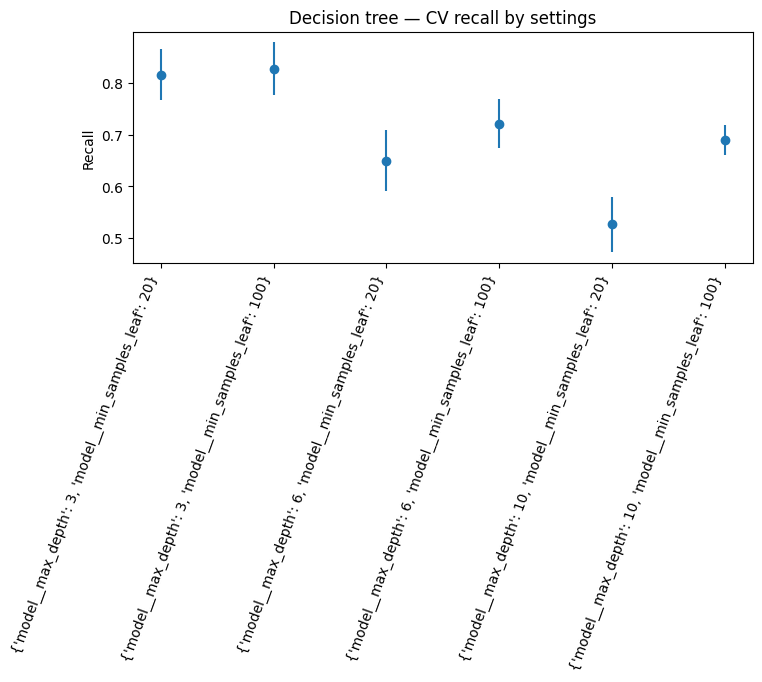

/tmp/ipykernel_823/913913606.py:4: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.figure(figsize=(8,3));plt.errorbar(range(len(group)),group.mean_test_score,yerr=group.std_test_score,fmt='o');plt.xticks(range(len(group)),[str(x) for x in group.params],rotation=70,ha='right');plt.title(name+' — CV recall by settings');plt.ylabel('Recall');plt.tight_layout();plt.show()


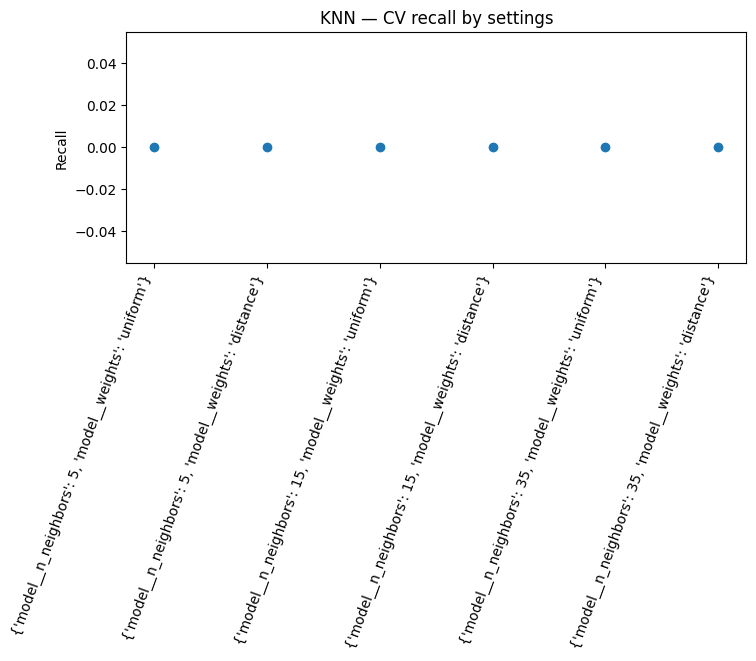

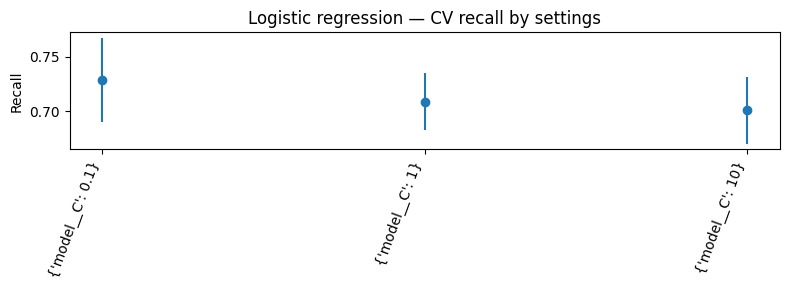

In [17]:
tuning_table=pd.concat(tuning,ignore_index=True)
display(tuning_table[['model','params','mean_test_score','std_test_score']].sort_values(['model','mean_test_score'],ascending=[True,False]))
for name,group in tuning_table.groupby('model'):
    plt.figure(figsize=(8,3));plt.errorbar(range(len(group)),group.mean_test_score,yerr=group.std_test_score,fmt='o');plt.xticks(range(len(group)),[str(x) for x in group.params],rotation=70,ha='right');plt.title(name+' — CV recall by settings');plt.ylabel('Recall');plt.tight_layout();plt.show()

## 7. One final evaluation on the held-out test set
Only now do we calculate test scores. The comparison includes the baseline first. Training vs CV vs test gaps can suggest overfitting or instability, but a single split is not proof.

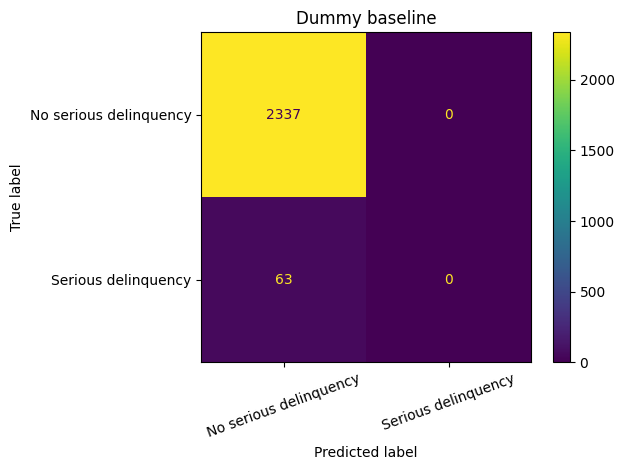

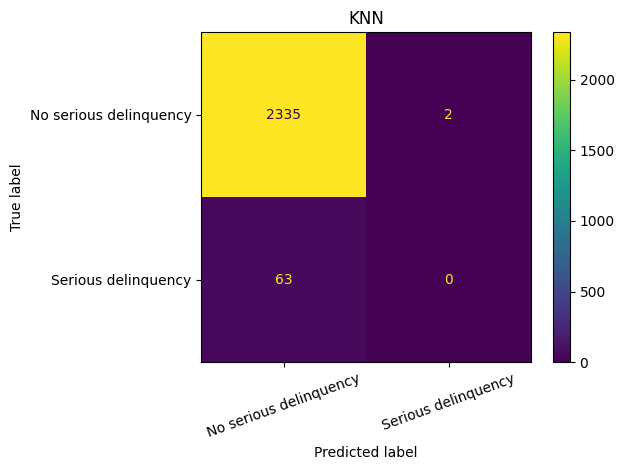

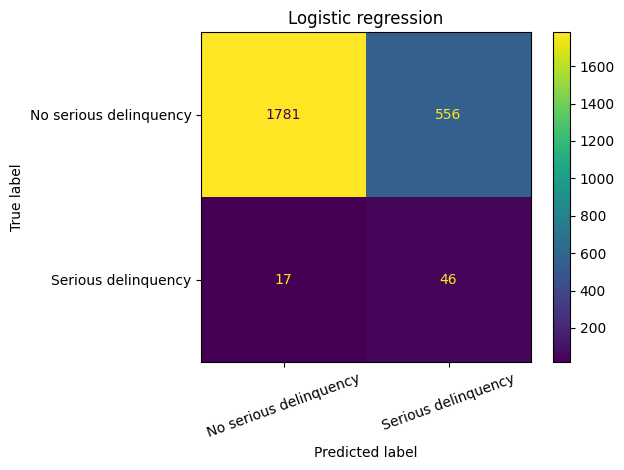

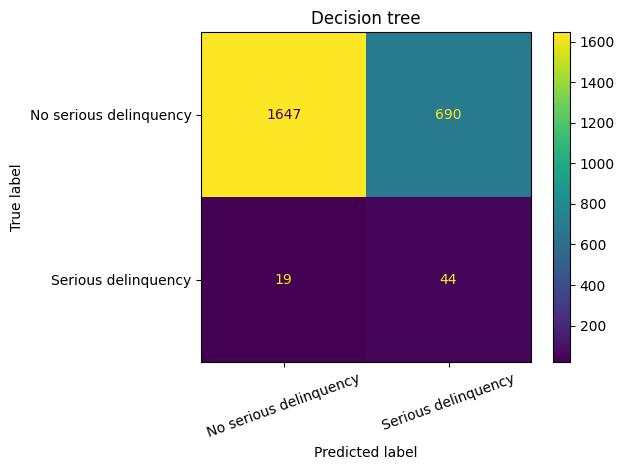

,model,best_params,train_recall,cv_recall_mean,cv_recall_std,test_precision,test_recall,test_f1
0,Dummy baseline,most_frequent,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,KNN,"{'model__n_neighbors': 5, 'model__weights': 'u...",0.031873,0.000000,0.000000,0.000000,0.000000,0.000000
2,Logistic regression,{'model__C': 0.1},0.820717,0.728868,0.038610,0.076412,0.730159,0.138346
3,Decision tree,"{'model__max_depth': 3, 'model__min_samples_le...",0.816733,0.828409,0.051175,0.059946,0.698413,0.110414


Saved model_comparison.csv


In [18]:
for i,row in comparison.iterrows():
    est=fitted[row['model']]; pred=est.predict(X_test)
    comparison.loc[i,'test_precision']=precision_score(y_test,pred,zero_division=0)
    comparison.loc[i,'test_recall']=recall_score(y_test,pred,zero_division=0)
    comparison.loc[i,'test_f1']=f1_score(y_test,pred,zero_division=0)
    ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=[0,1],display_labels=['No serious delinquency','Serious delinquency'],xticks_rotation=20)
    plt.title(row['model']);plt.tight_layout();plt.show()
display(comparison)
comparison.to_csv('model_comparison.csv',index=False)
print('Saved model_comparison.csv')

## 8. Errors and a group check
We compare false positives and false negatives for the best **cross-validation** model (not the best test score). Group comparisons by occupancy are descriptive; occupancy is not a protected demographic characteristic and this does not establish fairness.

In [19]:
candidate=comparison[comparison.model!='Dummy baseline'].sort_values('cv_recall_mean',ascending=False).iloc[0]['model']
chosen=fitted[candidate];pred=chosen.predict(X_test)
errors=X_test.copy();errors['actual']=y_test.to_numpy();errors['predicted']=pred
errors['error_type']=np.select([(errors.actual==1)&(errors.predicted==0),(errors.actual==0)&(errors.predicted==1)],['false negative','false positive'],default='correct')
print('CV-leading model:',candidate);display(errors.error_type.value_counts());display(errors.loc[errors.error_type!='correct'].head(10))
for group,part in errors.groupby('occupancy',dropna=False):
    if len(part)<20: continue
    print('Occupancy',group,'n=',len(part),'positives=',part.actual.sum(),'recall=',round(recall_score(part.actual,part.predicted,zero_division=0),3),'precision=',round(precision_score(part.actual,part.predicted,zero_division=0),3))

CV-leading model: Decision tree


,count
error_type,
correct,1691
false positive,690
false negative,19


,credit_score,first_time_homebuyer,num_units,occupancy,cltv,dti,original_upb,ltv,interest_rate,channel,state,property_type,loan_purpose,term,num_borrowers,actual,predicted,error_type
28307,699.0,N,1,P,90.0,39.0,250000,90.0,7.250,T,CO,MH,P,360,2.0,0,1,false positive
38358,699.0,N,1,P,80.0,21.0,66000,80.0,7.375,T,NC,MH,N,240,2.0,0,1,false positive
29531,585.0,N,1,P,80.0,45.0,208000,80.0,6.750,R,TN,CO,P,360,1.0,0,1,false positive
4342,644.0,N,1,P,80.0,35.0,138000,80.0,7.000,T,MI,CO,N,360,2.0,0,1,false positive
8192,656.0,N,1,P,80.0,NaN,200000,80.0,6.125,T,FL,SF,C,360,2.0,0,1,false positive
36307,628.0,N,1,P,80.0,18.0,112000,80.0,6.625,R,GA,SF,C,360,1.0,0,1,false positive
32854,810.0,N,1,S,80.0,45.0,247000,80.0,5.875,T,FL,PU,P,360,2.0,0,1,false positive
7455,605.0,Y,1,P,95.0,39.0,300000,95.0,6.375,R,IL,CO,P,360,2.0,0,1,false positive
14369,696.0,N,1,P,69.0,45.0,180000,69.0,6.125,T,PA,SF,P,360,2.0,0,1,false positive
16256,683.0,N,1,S,80.0,45.0,111000,80.0,6.375,R,AR,PU,P,360,2.0,0,1,false positive


Occupancy I n= 98 positives= 1 recall= 1.0 precision= 0.038
Occupancy P n= 2173 positives= 59 recall= 0.695 precision= 0.06
Occupancy S n= 129 positives= 3 recall= 0.667 precision= 0.074


## 9. Recommendation and live prediction
**Do not automatically deploy the CV-leading model.** Look at the comparison, especially precision and the number of false alerts, before deciding whether it is useful. The sample is historical, narrow and not representative of all subprime mortgages. The example below is fictional and should not be used for a real lending decision.

In [20]:
print('CV-leading model:',candidate)
print('Check its test precision, recall, F1 and false alerts above before recommending it.')
new_case={'credit_score':680,'first_time_homebuyer':'N','num_units':1,'occupancy':'P','cltv':85,'dti':40,'original_upb':220000,'ltv':85,'interest_rate':6.5,'channel':'R','state':'CA','property_type':'SF','loan_purpose':'P','term':360,'num_borrowers':1}
new_df=pd.DataFrame([new_case])[features]
print('Fictional mortgage prediction (1=serious delinquency):',int(chosen.predict(new_df)[0]))
if hasattr(chosen,'predict_proba'):print('Estimated class-1 probability:',round(float(chosen.predict_proba(new_df)[0,1]),3))
print('Important: a model probability is not necessarily calibrated to actual real-world risk.')

CV-leading model: Decision tree
Check its test precision, recall, F1 and false alerts above before recommending it.
Fictional mortgage prediction (1=serious delinquency): 1
Estimated class-1 probability: 0.67
Important: a model probability is not necessarily calibrated to actual real-world risk.


## 10. What the results mean (after running the notebook)

The 2006 Freddie Mac sample contained **50,000** origination records. After matching the repayment records and excluding loans without a clear 24-month negative outcome, **37,674 loans** had a usable target: **987 positive (2.62%)** and **36,687 negative (97.38%)**. We used a fixed, stratified subset of **12,000** for model training and testing (9,600 train / 2,400 test), mainly to keep KNN manageable in Colab.

| Model | Training recall | Cross-validation recall (mean ± SD) | Test precision | Test recall | Test F1 |
|---|---:|---:|---:|---:|---:|
| Dummy baseline | 0.000 | 0.000 ± 0.000 | 0.000 | 0.000 | 0.000 |
| KNN | 0.032 | 0.000 ± 0.000 | 0.000 | 0.000 | 0.000 |
| Logistic regression | 0.821 | 0.729 ± 0.039 | 0.076 | 0.730 | 0.138 |
| Decision tree | 0.817 | 0.828 ± 0.051 | 0.060 | 0.698 | 0.110 |

**Settings selected during cross-validation:** KNN: 5 neighbours, uniform weights; logistic regression: C = 0.1; decision tree: max depth = 3, min samples per leaf = 100. All models used the same train/test split and the same three cross-validation folds. Recall was the tuning metric, chosen before evaluating the test set.

The decision tree won on cross-validation recall, but its final test recall was lower. Logistic regression had higher test recall and precision, although we should not choose a winner simply by looking at the test scores. The decision tree missed **19** of the **63** actual positive loans in the test set and produced **690** false positives. This is a serious practical limitation. Its 0.670 probability for the fictional mortgage is an uncalibrated model output, **not** a reliable real-world default probability.

**Recommendation:** We would **not deploy any of these models for real lending or automatic risk decisions**. If an analyst wanted to continue experimenting, logistic regression is worth further research because it has better final test precision and F1, while the decision tree is easier to explain and led on training-only CV recall. Neither has demonstrated acceptable alert quality. This prototype is useful for investigating the modelling problem, not as a ready-to-use credit decision system.

**Ethics and fairness:** On the test set, the decision tree's occupancy-group recall was 1.00 for investor properties (only **one** positive), 0.695 for primary residences (59 positives), and 0.667 for second homes (three positives). Those small group counts mean we cannot draw reliable fairness conclusions. Occupancy is not a protected demographic category; we have no credible race/gender fairness assessment. Location and credit-score features may reflect historical inequality. We would need a newer dataset, protected-group assessment where lawful, external validation, probability calibration and a clearer business cost threshold before even considering a pilot.

**Important data limitation:** The target-building rule counts an observed serious delinquency as positive, but requires 24 known months to label a loan negative. This conservatively excludes early payoffs from the negative class; it can also change the apparent event rate. The 2006 sample is not representative of every subprime mortgage or mortgage applicant. Results should not be generalized to all borrowers or to today's market.

**One more reproducibility note:** The original Freddie Mac ZIP is not included in the public project package. Download `sample_2006.zip` through the official Freddie Mac site, upload it to Colab, and use **Runtime → Run all**. The output tables and confusion matrices above were preserved from the executed notebook submitted by the team. No new model run was performed when writing this explanation.
